# 15. Global optimization of the integrated posterior variance (NIPV)

Expected improvement looks for the minimum of a function. When the goal is
instead a *model* that is accurate everywhere (a surrogate for a simulator,
a map of a response surface), the next experiment should be the one that
removes the most uncertainty over the whole domain. Negative integrated
posterior variance (NIPV) measures exactly that.

Observing $y(x) = f(x) + \varepsilon$, $\varepsilon \sim \mathcal N(0, \tau^2)$,
lowers the posterior variance at any other point $x'$ by
$c(x, x')^2 / (\sigma^2(x) + \tau^2)$, where
$c(x, x') = k(x, x') - k_{x,Z} A\, k_{Z,x'}$ is the posterior covariance
and $A = (K + \tau^2 I)^{-1}$ (this does not depend on the value $y$ that
will be measured). Averaged over $M$ reference points $x'_j$ that cover the
domain,

$$ \mathrm{IPV}(x) = \frac1M \sum_{j=1}^M \sigma^2(x'_j)
   - \frac{\sum_j c(x, x'_j)^2}{M\,(\sigma^2(x) + \tau^2)}, \qquad
   \mathrm{NIPV}(x) = -\mathrm{IPV}(x), $$

the mean posterior variance *after* measuring at $x$. NIPV is the acquisition
function to maximize; it is BoTorch's `qNegIntegratedPosteriorVariance` with
$q = 1$ and the $x'_j$ as its `mc_points`. It is multimodal: zero gain at the
data, a bump in each gap between them, and the bumps compete.

`jaxglobal.gp.integrated_posterior_variance` builds IPV from two primitives:
`gp_cov` (the $M$ covariances $c(x, x'_j)$ at once, relaxed with the same
first-order RKHS model as `gp_mean`) and `gp_std`. So
`minimize(integrated_posterior_variance, ...)` maximizes NIPV with a proven
bound.

This notebook compares that certified solve with what one gets without
branch and bound, on time and on the value found:

1. **random sampling**: evaluate IPV at $n$ uniform points, keep the best;
2. **sampling + local polish**: the best sample refined with L-BFGS-B;
3. **multistart L-BFGS-B**: $k$ random starts with exact JAX gradients,
   keep the best (what Bayesian-optimization libraries do for this step);
4. **the plain `jnp` formula** in `minimize`, to show what the primitives buy.

It does this for one step in 2-D and in 4-D, and then along a 2-D
active-learning loop.

In [1]:
import os
import pathlib
import sys
import time

os.environ.setdefault("RUST_LOG", "warn")  # keep the local NLP solver's info messages out of the output
ROOT = pathlib.Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize as sp_minimize
from scipy.stats import qmc

import jaxglobal.bnb
from jaxglobal import kernels, minimize
from jaxglobal.gp import integrated_posterior_variance

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})
TOL = dict(abs_tol=1e-6, rel_tol=1e-4)


def solve(f, lo, hi, **kw):
    t = time.perf_counter()
    r = minimize(f, lo, hi, **TOL, **kw)
    t = time.perf_counter() - t
    # each IPV is a new problem solved once: drop its compiled kernels (see notebook 14)
    jaxglobal.bnb.clear_cache()
    jax.clear_caches()
    return r, t

## The GP and its IPV

Here the GP's hyperparameters are fixed, not fitted: a Matérn 5/2 kernel with
signal variance 1, length scale 0.4 on $[-1,1]^d$ and noise variance
$\tau^2 = 10^{-3}$. NIPV depends only on where the data are, not on the measured
values, so no test function is needed. The reference points are 64
scrambled Sobol points.

`make_ipv` returns IPV for `minimize`, and the same function written out in
`jnp` for comparison. The first check: both agree with conditioning the GP
on the data plus $x$ explicitly and averaging its variance over the $x'_j$.

In [2]:
KER = kernels.KERNELS["matern52"]
SF2, NOISE, ELL = 1.0, 1e-3, 0.4


def gram(P, Q, ls):
    return SF2 * np.asarray(KER(jnp.asarray((((P[:, None] - Q[None]) / ls) ** 2).sum(-1))))


def make_ipv(Z, Xref):
    ls = np.full(Z.shape[1], ELL)
    A = np.linalg.inv(gram(Z, Z, ls) + NOISE * np.eye(len(Z)))
    W = np.linalg.cholesky(A)
    Ur = W.T @ gram(Z, Xref, ls)
    v_ref = SF2 - (Ur**2).sum(0)

    def ipv(x):  # with the primitives
        return integrated_posterior_variance(x, Z, ls, A, SF2, Xref, NOISE)

    def ipv_jnp(x):  # the same formula in plain jnp
        u = W.T @ (SF2 * KER(jnp.sum(((x - Z) / ls) ** 2, -1)))
        c = SF2 * KER(jnp.sum(((x - Xref) / ls) ** 2, -1)) - Ur.T @ u
        return v_ref.mean() - (c @ c) / (len(Xref) * (jnp.maximum(SF2 - u @ u, 0.0) + NOISE))

    def brute(x):  # condition on Z and x explicitly
        Za = np.vstack([Z, x])
        Ka, Kr = gram(Za, Za, ls) + NOISE * np.eye(len(Za)), gram(Za, Xref, ls)
        return float(np.mean(SF2 - np.sum(Kr * np.linalg.solve(Ka, Kr), 0)))

    return ipv, ipv_jnp, brute, float(v_ref.mean())  # last: the mean variance now, before measuring


D = 2
LO, HI = -np.ones(D), np.ones(D)
Z2 = qmc.scale(qmc.LatinHypercube(d=D, seed=2).random(8), LO, HI)
XREF2 = qmc.scale(qmc.Sobol(D, seed=1).random(64), LO, HI)
ipv2, ipv2_jnp, brute2, _ = make_ipv(Z2, XREF2)
P = np.random.default_rng(0).uniform(LO, HI, (5, D))
pd.DataFrame(dict(primitives=[float(ipv2(jnp.asarray(p))) for p in P],
                  jnp_formula=[float(ipv2_jnp(jnp.asarray(p))) for p in P],
                  explicit_conditioning=[brute2(p) for p in P]))

,primitives,jnp_formula,explicit_conditioning
0,0.428774,0.428774,0.428774
1,0.442669,0.442669,0.442669
2,0.455654,0.455654,0.455654
3,0.449712,0.449712,0.449712
4,0.434173,0.434173,0.434173


## 1. One step in 2-D

The certified solve first, and the same solve with the `jnp` formula.

In [3]:
r2, t2 = solve(ipv2, LO, HI, time_limit=600)
print(f"primitives: {r2}\n  {t2:.1f} s")
r2j, t2j = solve(ipv2_jnp, LO, HI, time_limit=600)
print(f"jnp formula: {r2j}\n  {t2j:.1f} s")

primitives: Result(status='optimal', fun=0.40931158, lower_bound=0.40927081, gap=4.08e-05, x=[0.698339 0.119602], nodes=3055, iterations=24, time=5.83s)
  5.8 s


jnp formula: Result(status='optimal', fun=0.40931158, lower_bound=0.40927161, gap=4.00e-05, x=[0.698339 0.119602], nodes=11663, iterations=55, time=5.86s)
  5.9 s


Both certify the same maximum, NIPV $= -0.40931$ at $(0.698, 0.120)$, with a
proven bound $4\times10^{-5}$ away. The primitives need 3,055 nodes, the
`jnp` formula 11,663. On the first run on a 4-core VM both took 17 to 18 s,
most of it compiling the bounding kernels; the stored outputs, with
jaxglobal's on-disk kernel cache filled by that run, show 5.8 s and 5.9 s.
So on this problem the formula is good enough. The primitives matter when the noise is small
(with $\tau^2 = 10^{-4}$ and 10 clustered points, a test case in
`tests/test_gp.py` went from 458,000 nodes and 178 s to 1,900 nodes and
19 s) and in more dimensions (section 2).

The landscape, with every local maximum of NIPV that L-BFGS-B found from
200 random starts:

6 distinct local optima from 200 starts; certified optimum 0.409312; share of starts that reach it: 0.28


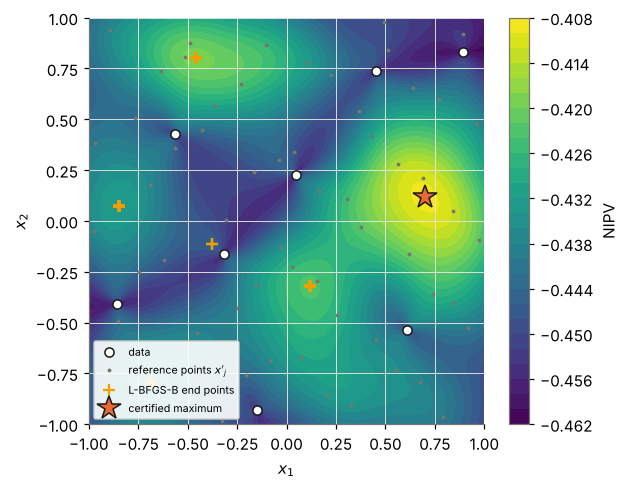

grid maximum of NIPV -0.409312, certified maximum -0.409312 (proven <= -0.409271)


In [4]:
vg2 = jax.jit(jax.value_and_grad(ipv2))
batch2 = jax.jit(jax.vmap(ipv2))


def local(vg, x0, lo, hi):
    r = sp_minimize(lambda x: [np.asarray(v, float) for v in vg(jnp.asarray(x))], x0, jac=True,
                    method="L-BFGS-B", bounds=list(zip(lo, hi)))
    return r.fun, r.x


vg2(jnp.zeros(D)), batch2(jnp.zeros((2, D)))  # compile once, outside the timings below
ends = [local(vg2, x0, LO, HI) for x0 in np.random.default_rng(1).uniform(LO, HI, (200, D))]
ends_f, ends_x = np.array([e[0] for e in ends]), np.array([e[1] for e in ends])
uniq = np.unique(np.round(ends_f, 6))
print(f"{len(uniq)} distinct local optima from 200 starts; certified optimum {r2.fun:.6f}; "
      f"share of starts that reach it: {np.mean(ends_f <= r2.fun + 1e-6):.2f}")

g = np.linspace(-1, 1, 301)
G = jnp.asarray(np.stack(np.meshgrid(g, g), -1).reshape(-1, 2))
grid = np.asarray(batch2(G))
fig, ax = plt.subplots(figsize=(5.8, 4.8))
cs = ax.contourf(g, g, -grid.reshape(301, 301), levels=30, cmap="viridis")
fig.colorbar(cs, ax=ax, label="NIPV")
ax.plot(*Z2.T, "o", color="white", mec=INK, ms=6, label="data")
ax.plot(*XREF2.T, ".", color=MUTED, ms=3, label="reference points $x'_j$")
ax.plot(*ends_x.T, "+", color=YELLOW, ms=8, mew=1.5, label="L-BFGS-B end points")
ax.plot(*r2.x, "*", color=ORANGE, mec=INK, ms=16, label="certified maximum")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.legend(fontsize=7, loc="lower left", framealpha=0.9)
plt.show()
print(f"grid maximum of NIPV {-grid.min():.6f}, certified maximum {-r2.fun:.6f} (proven <= {-r2.lower_bound:.6f})")

Now the comparison. Each sampling or multistart method is repeated 50
times with different random numbers; a run "finds the optimum" if its IPV
is within the solver's tolerance of the certified value. Times are per run,
with the JAX functions already compiled (their one-time compile is listed
separately); the branch-and-bound time includes its compile.

In [5]:
def compare(ipv, vg, batch, r, t, lo, hi, reps=50, samples=(100, 1_000, 10_000, 100_000), starts=(1, 2, 5, 10, 20)):
    d = len(lo)
    tol = TOL["abs_tol"] + TOL["rel_tol"] * abs(r.fun)
    t0 = time.perf_counter()
    jax.jit(jax.value_and_grad(ipv))(jnp.zeros(d))
    for n in samples:
        jax.jit(jax.vmap(ipv))(jnp.zeros((n, d)))
    compile_s = time.perf_counter() - t0
    rng = np.random.default_rng(0)
    rows = [dict(method="branch and bound (certified)", found_optimum=1.0, best_IPV=r.fun, median_IPV=r.fun, worst_IPV=r.fun,
                 gap_to_bound_worst=r.fun - r.lower_bound, time_s=t)]

    def add(name, runs):
        f = np.array([v for v, _ in runs])
        rows.append(dict(method=name, found_optimum=np.mean(f <= r.fun + tol), best_IPV=f.min(), median_IPV=np.median(f),
                         worst_IPV=f.max(), gap_to_bound_worst=f.max() - r.lower_bound,
                         time_s=np.mean([s for _, s in runs])))

    for n in samples:
        plain, polished = [], []
        for _ in range(reps):
            t0 = time.perf_counter()
            X = rng.uniform(lo, hi, (n, d))
            F = np.asarray(batch(jnp.asarray(X)))
            ts = time.perf_counter() - t0
            plain.append((F.min(), ts))
            t0 = time.perf_counter()
            fl, _ = local(vg, X[F.argmin()], lo, hi)
            polished.append((fl, ts + time.perf_counter() - t0))
        add(f"random sampling, n = {n:,}", plain)
        add(f"sampling n = {n:,} + L-BFGS-B", polished)
    for k in starts:
        runs = []
        for _ in range(reps):
            t0 = time.perf_counter()
            best = min(local(vg, x0, lo, hi)[0] for x0 in rng.uniform(lo, hi, (k, d)))
            runs.append((best, time.perf_counter() - t0))
        add(f"multistart L-BFGS-B, {k} start{'s' if k > 1 else ''}", runs)
    print(f"one-time JIT compile of the IPV value/gradient and batch functions: {compile_s:.1f} s")
    return pd.DataFrame(rows)


res2 = compare(ipv2, vg2, batch2, r2, t2, LO, HI)
res2

one-time JIT compile of the IPV value/gradient and batch functions: 0.5 s


,method,found_optimum,best_IPV,median_IPV,worst_IPV,gap_to_bound_worst,time_s
0,branch and bound (certified),1.00,0.409312,0.409312,0.409312,0.000041,5.827531
1,"random sampling, n = 100",0.02,0.409330,0.410594,0.420111,0.010841,0.002412
2,sampling n = 100 + L-BFGS-B,1.00,0.409312,0.409312,0.409312,0.000041,0.005469
3,"random sampling, n = 1,000",0.20,0.409313,0.409420,0.410217,0.000946,0.003707
4,"sampling n = 1,000 + L-BFGS-B",1.00,0.409312,0.409312,0.409312,0.000041,0.006178
5,"random sampling, n = 10,000",0.94,0.409312,0.409322,0.409370,0.000099,0.013112
6,"sampling n = 10,000 + L-BFGS-B",1.00,0.409312,0.409312,0.409312,0.000041,0.015872
7,"random sampling, n = 100,000",1.00,0.409312,0.409313,0.409320,0.000049,0.089932
8,"sampling n = 100,000 + L-BFGS-B",1.00,0.409312,0.409312,0.409312,0.000041,0.093403
9,"multistart L-BFGS-B, 1 start",0.28,0.409312,0.419327,0.432241,0.022970,0.002473


The same runs as time against the gap to the certified optimum, for the best,
median and worst of the 50 runs. A gap below $10^{-8}$ (L-BFGS-B's own
tolerance) is shown as 0; the branch-and-bound row is 0 by definition, and
its proven gap to the lower bound is in `gap_to_bound_worst` above.

In [6]:
def gap_table(res, r):
    out = pd.DataFrame({"method": res.method, "time_ms": 1e3 * res.time_s})
    for k in ("best", "median", "worst"):
        g = res[f"{k}_IPV"] - r.fun
        out[f"{k}_gap"] = g.where(g > 1e-8, 0.0)
    return out.style.format({"time_ms": "{:,.1f}", "best_gap": "{:.1e}", "median_gap": "{:.1e}",
                             "worst_gap": "{:.1e}"}).hide(axis="index")


gap_table(res2, r2)

method,time_ms,best_gap,median_gap,worst_gap
branch and bound (certified),"5,827.5",0.0e+00,0.0e+00,0.0e+00
"random sampling, n = 100",2.4,1.8e-05,1.3e-03,1.1e-02
sampling n = 100 + L-BFGS-B,5.5,0.0e+00,0.0e+00,0.0e+00
"random sampling, n = 1,000",3.7,1.5e-06,1.1e-04,9.1e-04
"sampling n = 1,000 + L-BFGS-B",6.2,0.0e+00,0.0e+00,0.0e+00
"random sampling, n = 10,000",13.1,8.4e-08,1.0e-05,5.8e-05
"sampling n = 10,000 + L-BFGS-B",15.9,0.0e+00,0.0e+00,0.0e+00
"random sampling, n = 100,000",89.9,2.0e-08,1.1e-06,8.0e-06
"sampling n = 100,000 + L-BFGS-B",93.4,0.0e+00,0.0e+00,0.0e+00
"multistart L-BFGS-B, 1 start",2.5,0.0e+00,1.0e-02,2.3e-02


NIPV has six local maxima here, and only 28% of L-BFGS-B starts end at the
global one: the others stop at bumps between other pairs of data points
(the yellow crosses). The certified value matches the maximum over a
$301\times301$ grid.

In the first table, `gap_to_bound_worst` is the worst IPV of 50 runs minus the
certified *lower* bound, so $4.1\times10^{-5}$ (the solver's tolerance) means
"found the optimum" and anything larger is the suboptimality proven to be at
least that much minus $4\times10^{-5}$.

* **Random sampling alone** is slow to converge: it needs 10,000 points to
  find the optimum in 94% of runs and 100,000 for all of them, and even
  then it stops a few $10^{-6}$ short because it never lands exactly on the
  maximizer.
* **Sampling + one L-BFGS-B polish** found the optimum in every run, even
  from the best of 100 samples (4 ms): in 2-D 100 samples are enough to
  land in the right basin.
* **Multistart L-BFGS-B** is the weak one here: with one start it finds the
  optimum in 28% of runs (the same 28% as above), with 5 starts in 76% and
  with 10 in 96%. A miss stops at the second-best bump, $\mathrm{IPV} =
  0.4193$ against $0.4093$: it gives up a fifth of the variance reduction
  available at this step (from $0.4615$ to $0.4093$), and nothing in its
  result says so.
* **Branch and bound** takes about 6 s with the kernel cache warm (18 s on
  the first run), against milliseconds for all the others,
  and is the only one that says how far from the optimum it can be.

The gap table separates the two ways of missing. Every method with a
local polish has a best gap of 0: when it starts in the right basin,
L-BFGS-B lands on the optimum to its own tolerance, so its misses are whole
basins (the second-best maximum is $10^{-2}$ worse). Sampling alone never
reaches 0; its error shrinks smoothly with $n$, about tenfold per tenfold
more points, from $1.3\times10^{-3}$ (median, $n = 100$) to
$1.1\times10^{-6}$ ($n = 100{,}000$). The cheapest methods whose worst run
was 0 are 100 samples + L-BFGS-B (5.5 ms) and 20-start multistart (59 ms),
about 1,000 and 100 times faster than branch and bound.

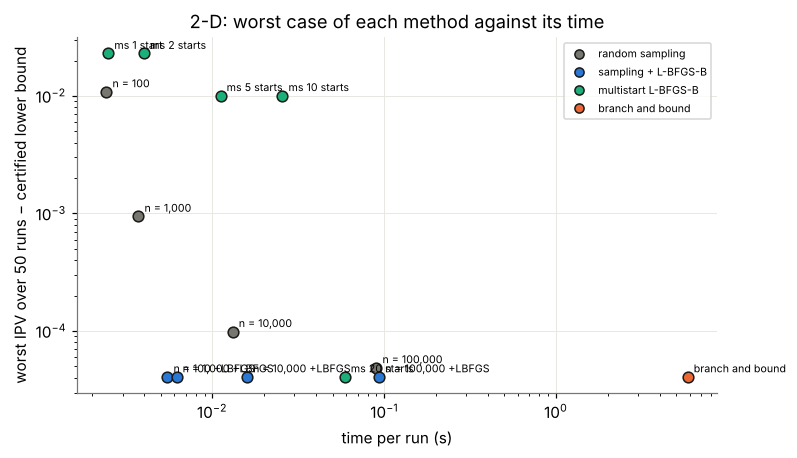

In [7]:
def plot_compare(res, title):
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    cols = {"random": MUTED, "sampling": BLUE, "multistart": AQUA, "branch": ORANGE}
    for _, row in res.iterrows():
        c = next(v for k, v in cols.items() if row.method.startswith(k))
        ax.plot(row.time_s, max(row.gap_to_bound_worst, 1e-9), "o", color=c, mec=INK, ms=7)
        ax.annotate(row.method.replace("multistart L-BFGS-B, ", "ms ").replace("random sampling, ", "")
                    .replace("sampling ", "").replace(" + L-BFGS-B", " +LBFGS").replace(" (certified)", ""),
                    (row.time_s, max(row.gap_to_bound_worst, 1e-9)), xytext=(4, 3), textcoords="offset points", fontsize=7)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("time per run (s)")
    ax.set_ylabel("worst IPV over 50 runs − certified lower bound")
    ax.set_title(title)
    for k, v in cols.items():
        ax.plot([], [], "o", color=v, mec=INK, label={"random": "random sampling", "sampling": "sampling + L-BFGS-B",
                                                      "multistart": "multistart L-BFGS-B", "branch": "branch and bound"}[k])
    ax.legend(fontsize=7)
    plt.show()


plot_compare(res2, "2-D: worst case of each method against its time")

## 2. One step in 4-D

The same comparison with $d = 4$, 12 data points and 128 reference points.

In [8]:
D4 = 4
LO4, HI4 = -np.ones(D4), np.ones(D4)
Z4 = qmc.scale(qmc.LatinHypercube(d=D4, seed=4).random(12), LO4, HI4)
XREF4 = qmc.scale(qmc.Sobol(D4, seed=1).random(128), LO4, HI4)
ipv4, ipv4_jnp, _, _ = make_ipv(Z4, XREF4)
r4, t4 = solve(ipv4, LO4, HI4, time_limit=1200)
print(f"primitives: {r4}\n  {t4:.1f} s")
r4j, t4j = solve(ipv4_jnp, LO4, HI4, time_limit=1200)
print(f"jnp formula: {r4j}\n  {t4j:.1f} s")
vg4 = jax.jit(jax.value_and_grad(ipv4))
res4 = compare(ipv4, vg4, jax.jit(jax.vmap(ipv4)), r4, t4, LO4, HI4)
res4

primitives: Result(status='optimal', fun=0.88057364, lower_bound=0.88048559, gap=8.81e-05, x=[-0.3693   -0.494219  0.69308   0.347492], nodes=105355, iterations=419, time=110.87s)
  110.9 s


jnp formula: Result(status='optimal', fun=0.88057364, lower_bound=0.88048563, gap=8.80e-05, x=[-0.3693   -0.494219  0.69308   0.347492], nodes=272293, iterations=1071, time=222.51s)
  222.5 s


one-time JIT compile of the IPV value/gradient and batch functions: 1.0 s


,method,found_optimum,best_IPV,median_IPV,worst_IPV,gap_to_bound_worst,time_s
0,branch and bound (certified),1.00,0.880574,0.880574,0.880574,0.000088,110.870587
1,"random sampling, n = 100",0.00,0.882951,0.885349,0.887628,0.007143,0.003652
2,sampling n = 100 + L-BFGS-B,0.22,0.880574,0.882342,0.885342,0.004856,0.008585
3,"random sampling, n = 1,000",0.00,0.880898,0.883262,0.884744,0.004258,0.004670
4,"sampling n = 1,000 + L-BFGS-B",0.76,0.880574,0.880574,0.883166,0.002680,0.008334
5,"random sampling, n = 10,000",0.00,0.880749,0.881777,0.883111,0.002625,0.026273
6,"sampling n = 10,000 + L-BFGS-B",0.96,0.880574,0.880574,0.882342,0.001856,0.030454
7,"random sampling, n = 100,000",0.02,0.880662,0.881021,0.881518,0.001033,0.168432
8,"sampling n = 100,000 + L-BFGS-B",1.00,0.880574,0.880574,0.880574,0.000088,0.174396
9,"multistart L-BFGS-B, 1 start",0.08,0.880574,0.884124,0.890489,0.010004,0.005354


In [9]:
gap_table(res4, r4)

method,time_ms,best_gap,median_gap,worst_gap
branch and bound (certified),"110,870.6",0.0e+00,0.0e+00,0.0e+00
"random sampling, n = 100",3.7,2.4e-03,4.8e-03,7.1e-03
sampling n = 100 + L-BFGS-B,8.6,0.0e+00,1.8e-03,4.8e-03
"random sampling, n = 1,000",4.7,3.2e-04,2.7e-03,4.2e-03
"sampling n = 1,000 + L-BFGS-B",8.3,0.0e+00,0.0e+00,2.6e-03
"random sampling, n = 10,000",26.3,1.8e-04,1.2e-03,2.5e-03
"sampling n = 10,000 + L-BFGS-B",30.5,0.0e+00,0.0e+00,1.8e-03
"random sampling, n = 100,000",168.4,8.8e-05,4.5e-04,9.4e-04
"sampling n = 100,000 + L-BFGS-B",174.4,0.0e+00,0.0e+00,0.0e+00
"multistart L-BFGS-B, 1 start",5.4,0.0e+00,3.6e-03,9.9e-03


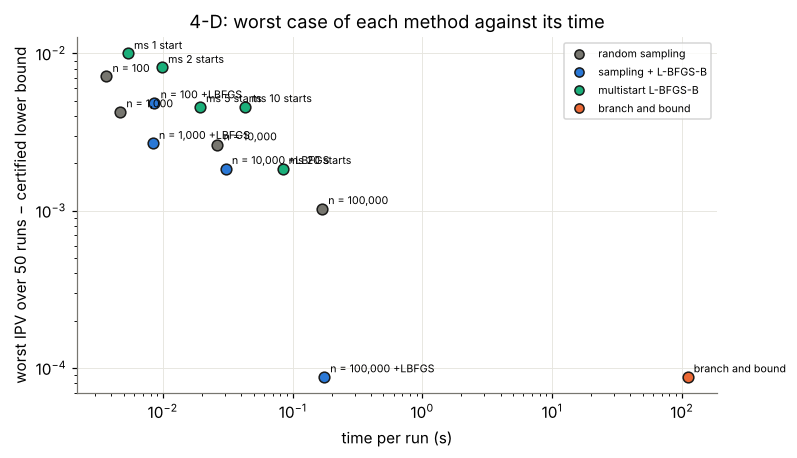

In [10]:
plot_compare(res4, "4-D: worst case of each method against its time")

The gap table in 4-D: the best run of every polished method is still 0,
but the median of 1- to 10-start multistart and of 100 samples + L-BFGS-B
is a whole basin off ($1.8\times10^{-3}$ to $3.6\times10^{-3}$). Sampling alone
gets no closer than $8.8\times10^{-5}$ in its best run with 100,000 points,
about the certified solve's own gap. The only heuristic with a worst gap
of 0 is 100,000 samples + L-BFGS-B, at 174 ms, about 600 times faster than
branch and bound (111 s).

In 4-D the certified solve takes 105,000 nodes and 111 s with the
primitives (140 s on the first run), and 272,000 nodes and 222 s with the
`jnp` formula. The
heuristics now miss much more often:

* random sampling alone does not find the optimum even with 100,000 points;
* sampling + L-BFGS-B needs the best of 10,000 samples to find it in 96%
  of runs and 100,000 for all 50;
* multistart L-BFGS-B finds it in 8% of runs with one start, 38% with five
  and 76% with twenty; the worst of the 20-start runs stops at
  $\mathrm{IPV} = 0.8823$ against $0.8806$.

The cheapest method that never missed in these 50 runs is 100,000 samples
+ L-BFGS-B (0.19 s), and that is known only because branch and bound
gave the reference. Its time is fixed by the sample count, which has to
grow with the dimension; how many samples are enough in 6-D is again a
question only a certificate answers.

## 3. Along an active-learning loop (2-D)

Each step adds the point that maximizes NIPV and refits nothing else (the
hyperparameters are fixed). At every step the certified solve is compared
with 5-start multistart and with 1,000 random samples polished by L-BFGS-B,
each repeated 20 times; the loop itself follows the certified point. The
last column is the share of the IPV reduction available at that step that
the worst multistart run leaves behind.

In [11]:
Z, rows, picks = Z2.copy(), [], []
for step in range(8):
    ipv, _, _, now = make_ipv(Z, XREF2)
    r, t = solve(ipv, LO, HI, time_limit=600)
    vg, batch = jax.jit(jax.value_and_grad(ipv)), jax.jit(jax.vmap(ipv))
    vg(jnp.zeros(D)), batch(jnp.zeros((1000, D)))
    rng = np.random.default_rng(step)
    ms, sp, tms = [], [], []
    for _ in range(20):
        t0 = time.perf_counter()
        ms.append(min(local(vg, x0, LO, HI)[0] for x0 in rng.uniform(LO, HI, (5, D))))
        tms.append(time.perf_counter() - t0)
        X = rng.uniform(LO, HI, (1000, D))
        sp.append(local(vg, X[np.asarray(batch(jnp.asarray(X))).argmin()], LO, HI)[0])
    tol = TOL["abs_tol"] + TOL["rel_tol"] * abs(r.fun)
    rows.append(dict(step=step, N=len(Z), status=r.status, IPV_certified=r.fun, lower_bound=r.lower_bound,
                     nodes=r.nodes, bb_time_s=t, multistart5_found=np.mean(np.array(ms) <= r.fun + tol),
                     multistart5_worst=max(ms), multistart5_time_s=np.mean(tms),
                     sample1000_lbfgs_found=np.mean(np.array(sp) <= r.fun + tol),
                     IPV_before=now, lost_share_worst_ms5=(max(ms) - r.fun) / (now - r.fun)))
    picks.append(r.x)
    Z = np.vstack([Z, r.x])
loop = pd.DataFrame(rows)
loop

,step,N,status,IPV_certified,lower_bound,nodes,bb_time_s,multistart5_found,multistart5_worst,multistart5_time_s,sample1000_lbfgs_found,IPV_before,lost_share_worst_ms5
0,0,8,optimal,0.409312,0.409271,3055,3.470665,0.75,0.423573,0.016702,1.0,0.461534,0.273091
1,1,9,optimal,0.367154,0.367119,3551,3.520442,0.80,0.371957,0.016798,1.0,0.409312,0.113931
2,2,10,optimal,0.329809,0.329777,3867,4.199961,0.85,0.339347,0.012237,1.0,0.367154,0.255383
3,3,11,optimal,0.299056,0.299028,4113,3.963834,0.60,0.307794,0.013016,1.0,0.329809,0.284139
4,4,12,optimal,0.272762,0.272736,5081,4.237960,0.55,0.276424,0.014764,0.9,0.299056,0.139277
5,5,13,optimal,0.246827,0.246803,4931,4.373983,0.60,0.255778,0.013700,1.0,0.272762,0.345132
6,6,14,optimal,0.224820,0.224798,5193,3.963433,0.70,0.231037,0.015983,1.0,0.246827,0.282510
7,7,15,optimal,0.204328,0.204308,5443,4.631059,0.60,0.210515,0.013698,1.0,0.224820,0.301944


Every step is certified (`status`, and `lower_bound` within $4\times10^{-5}$
of `IPV_certified`), in 3,000 to 5,500 nodes. On the first run a step took
about 20 s, almost all of it compiling, because each new data set is a new
function for jaxglobal; the stored outputs, from a second run with the
kernel cache filled, show 3.5 to 4.6 s. The
mean posterior variance over the reference points drops from 0.46 to 0.20
in 8 steps.

Five-start multistart finds the certified point in 55% to 85% of the runs
per step. Its worst run gives up 11% to 35% of the reduction available at
that step. A thousand samples polished by L-BFGS-B finds it in all runs
but one (step 4, 18 of 20).

## Summary

* NIPV is the mean posterior variance over reference points after one more
  measurement. With `integrated_posterior_variance` (built from `gp_cov`
  and `gp_std`) it is a plain JAX function, and `minimize` returns its
  maximum with a proven bound: 4 to 6 s in 2-D and 110 s in 4-D on a 4-core VM
  with the kernel cache warm (18 s and 140 s on the first run, compiling
  included).
* It is multimodal (six local maxima in the 2-D example), and multistart
  L-BFGS-B, the usual inner optimizer in Bayesian optimization, misses the
  global one often: 24% of 5-start runs in 2-D, 24% of 20-start runs in
  4-D, with no sign in its result.
* Dense sampling followed by one local polish was much more reliable than
  multistart on these problems, and hundreds of times faster than branch
  and bound. How many samples are enough depends on the dimension (100 in
  2-D, 100,000 in 4-D here); the certified solve is how to find out.
* The primitives cut the node count against the `jnp` formula by 4× in 2-D
  and 2.6× in 4-D here, and by 245× when the noise is small; on the 2-D
  problem the solve times were the same (5.8 s and 5.9 s).

Not covered: batch NIPV ($q > 1$ points at once), and fitting the
hyperparameters, which does not change the optimization (NIPV depends on
them only through constants).